<a href="https://colab.research.google.com/github/AntonyRMV26/INGENIERIA-DEL-CONOCIMIENTO/blob/master/Tarea_Sesion10_energia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sesión 10-A | Pronóstico de consumo eléctrico doméstico (LSTM y GRU)
**Ingeniería del Conocimiento - Práctica básica de series de tiempo**

**Objetivo:** predecir el valor de la siguiente observación de una serie temporal mediante dos arquitecturas recurrentes, **LSTM** y **GRU**, y comparar sus resultados.

**Problema:** predecir el consumo de los electrodomésticos en el siguiente intervalo de 10 minutos a partir de las 3 horas anteriores. Es una práctica educativa relacionada con la planificación energética.

**Fuente de datos:** UCI Machine Learning Repository - Appliances Energy Prediction (Candanedo, 2017)  
https://archive.ics.uci.edu/dataset/374/appliances-energy-prediction  
**Variable objetivo:** `Appliances` (Wh por intervalo de 10 min).

**Referencia de clase:** `Semana10_A_rnn_lstm_gru.ipynb` (Ejemplos 1 y 2). Se conserva el esquema de carga, análisis, división cronológica, ventanas deslizantes, normalización, LSTM/GRU, entrenamiento y evaluación. Se emplea únicamente una serie univariada para mantener el alcance básico.

> Esta es una tarea de **aprendizaje supervisado por regresión**: la etiqueta es el valor numérico del siguiente instante. Las métricas solo se conocen después de ejecutar el entrenamiento.

## 1. Bibliotecas y configuración

In [ ]:
# Bibliotecas necesarias; disponibles normalmente en Google Colab.
from pathlib import Path
from urllib.request import urlretrieve
import zipfile
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

DATOS = Path('/content/datos_sesion10' if Path('/content').exists() else 'datos_sesion10')
RESULTADOS = Path('/content/resultados_sesion10' if Path('/content').exists() else 'resultados_sesion10')
DATOS.mkdir(parents=True, exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__)
print('GPU disponible:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU disponible: []


## 2. Descargar el dataset y observar la información

In [ ]:
# Descarga del archivo ZIP desde la página oficial de UCI.
URL = 'https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip'
ZIP = DATOS / 'energia_uci.zip'
if not ZIP.exists():
    try:
        urlretrieve(URL, ZIP)
    except Exception as error:
        raise RuntimeError(
            'No se pudo descargar el dataset. Abrir la fuente UCI y descargar '
            'el ZIP manualmente; guardarlo en: ' + str(ZIP)
        ) from error

# Se lee el CSV sin extraer manualmente los archivos.
with zipfile.ZipFile(ZIP, 'r') as archivo:
    encontrados = [n for n in archivo.namelist()
                   if n.lower().endswith('energydata_complete.csv')]
    if not encontrados:
        raise FileNotFoundError('No se encontró energydata_complete.csv dentro del ZIP.')
    with archivo.open(encontrados[0]) as f:
        df = pd.read_csv(f)

print('Dimensiones originales:', df.shape)
print('Columnas:', list(df.columns))
display(df.head())

Dimensiones originales: (19735, 29)
Columnas: ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
# Se convierte la fecha a tipo datetime y se ordenan las observaciones.
df['fecha'] = pd.to_datetime(df['date'])
df = df.sort_values('fecha').drop_duplicates('fecha').reset_index(drop=True)

# 'Appliances' representa consumo de electrodomésticos, medido en Wh.
serie = df[['fecha', 'Appliances']].rename(columns={'Appliances': 'valor'}).copy()
serie['valor'] = pd.to_numeric(serie['valor'], errors='coerce')
serie = serie.dropna().reset_index(drop=True)

FRECUENCIA = np.timedelta64(10, 'm')
VENTANA = 18  # 18 registros de 10 min = 3 horas de información anterior.

print('Registros utilizables:', len(serie))
print('Intervalos distintos a 10 minutos:',
      int(serie['fecha'].diff().dropna().ne(pd.Timedelta(minutes=10)).sum()))
display(serie.head())

Registros utilizables: 19735
Intervalos distintos a 10 minutos: 0


,fecha,valor
0,2016-01-11 17:00:00,60
1,2016-01-11 17:10:00,60
2,2016-01-11 17:20:00,50
3,2016-01-11 17:30:00,50
4,2016-01-11 17:40:00,60


Valores faltantes: 0
Mínimo: 10 | Máximo: 1080


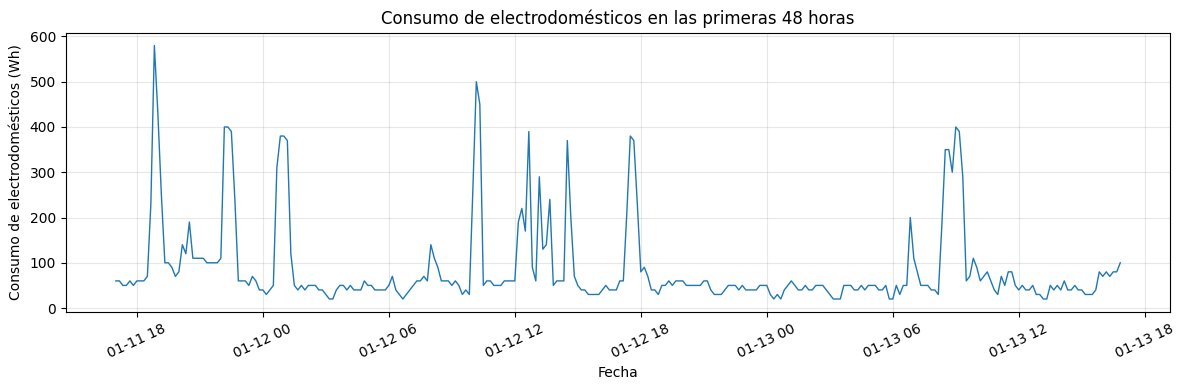

In [ ]:
# Gráfico de una parte de la serie para reconocer sus cambios en el tiempo.
print('Valores faltantes:', int(serie['valor'].isna().sum()))
print('Mínimo:', serie['valor'].min(), '| Máximo:', serie['valor'].max())
fig, ax = plt.subplots(figsize=(12, 4))
vista = serie.iloc[:288]
ax.plot(vista['fecha'], vista['valor'], linewidth=1.0)
ax.set(title='Consumo de electrodomésticos en las primeras 48 horas', xlabel='Fecha', ylabel='Consumo de electrodomésticos (Wh)')
ax.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 3. Separación cronológica y normalización

Se utiliza 70 % de los registros más antiguos para entrenar, 15 % siguientes para validar y 15 % finales para probar. **No se mezclan aleatoriamente.** El escalador se ajusta solo sobre entrenamiento para evitar fuga de información temporal.

Train: 13814
Validación: 2960
Test: 2961
Rango normalizado de entrenamiento: (0.0, 1.0)


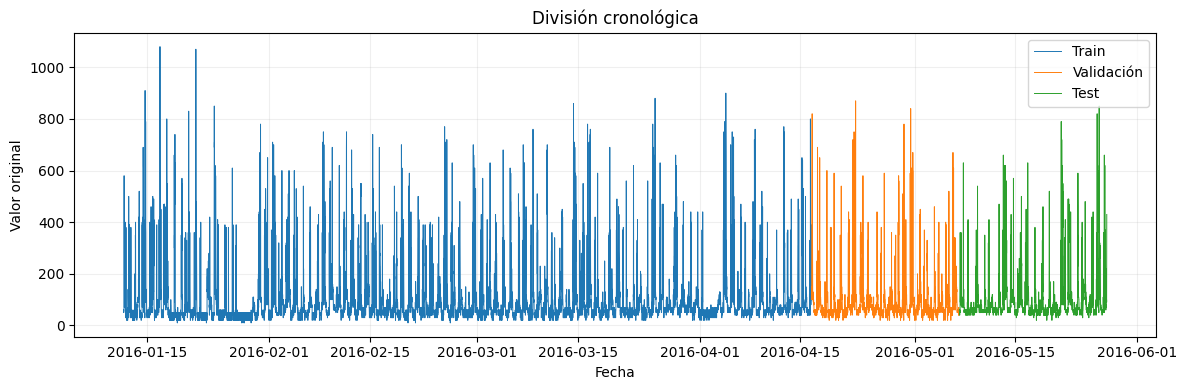

In [ ]:
# División cronológica de la serie original.
n = len(serie)
fin_train = int(n * 0.70)
fin_val = int(n * 0.85)

valores = serie['valor'].to_numpy(dtype=np.float32)
fechas = serie['fecha'].to_numpy(dtype='datetime64[ns]')

# MinMaxScaler aprende el mínimo y el máximo solo de entrenamiento.
scaler = MinMaxScaler()
scaler.fit(valores[:fin_train].reshape(-1, 1))
valores_norm = scaler.transform(valores.reshape(-1, 1)).ravel().astype(np.float32)

print('Train:', fin_train)
print('Validación:', fin_val - fin_train)
print('Test:', n - fin_val)
print('Rango normalizado de entrenamiento:',
      (float(valores_norm[:fin_train].min()), float(valores_norm[:fin_train].max())))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie['fecha'].iloc[:fin_train], valores[:fin_train], label='Train', lw=0.7)
ax.plot(serie['fecha'].iloc[fin_train:fin_val], valores[fin_train:fin_val], label='Validación', lw=0.7)
ax.plot(serie['fecha'].iloc[fin_val:], valores[fin_val:], label='Test', lw=0.7)
ax.set(title='División cronológica', xlabel='Fecha', ylabel='Valor original')
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 4. Ventanas deslizantes (X, y)

Cada muestra contiene una secuencia anterior (`X`) y el valor numérico del instante siguiente (`y`). Las ventanas de validación y test pueden usar **solo observaciones anteriores** como contexto. Si faltan registros temporales, la ventana se descarta para conservar la frecuencia real.

In [ ]:
def crear_ventanas(valores_escalados, fechas, inicio, fin, ventana, frecuencia):
    # Solo se predicen objetivos comprendidos en el periodo indicado.
    X, y, momentos = [], [], []
    for i in range(max(inicio, ventana), fin):
        bloque_fechas = fechas[i - ventana:i + 1]
        # Evita tratar horas o minutos faltantes como intervalos consecutivos.
        if not np.all(np.diff(bloque_fechas) == frecuencia):
            continue
        X.append(valores_escalados[i - ventana:i])
        y.append(valores_escalados[i])
        momentos.append(fechas[i])
    return (np.asarray(X, dtype=np.float32)[..., np.newaxis],
            np.asarray(y, dtype=np.float32),
            np.asarray(momentos))

X_train, y_train, t_train = crear_ventanas(
    valores_norm, fechas, VENTANA, fin_train, VENTANA, FRECUENCIA)
X_val, y_val, t_val = crear_ventanas(
    valores_norm, fechas, fin_train, fin_val, VENTANA, FRECUENCIA)
X_test, y_test, t_test = crear_ventanas(
    valores_norm, fechas, fin_val, n, VENTANA, FRECUENCIA)

# Forma: (número de muestras, pasos temporales, características).
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_val:  ', X_val.shape, 'y_val:  ', y_val.shape)
print('X_test: ', X_test.shape, 'y_test: ', y_test.shape)
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1:] == (VENTANA, 1)

X_train: (13796, 18, 1) y_train: (13796,)
X_val:   (2960, 18, 1) y_val:   (2960,)
X_test:  (2961, 18, 1) y_test:  (2961,)


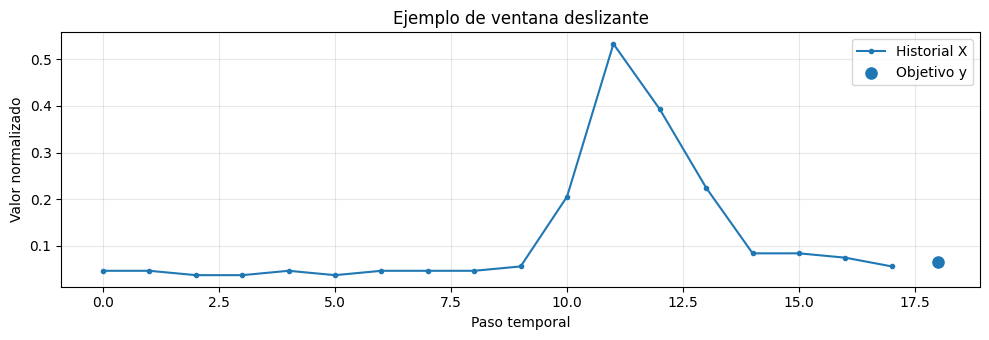

In [ ]:
# Ejemplo visual de cómo la ventana predice el siguiente valor.
ejemplo = 0
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(range(VENTANA), X_train[ejemplo, :, 0], marker='.', label='Historial X')
ax.scatter([VENTANA], [y_train[ejemplo]], s=65, label='Objetivo y')
ax.set(xlabel='Paso temporal', ylabel='Valor normalizado',
       title='Ejemplo de ventana deslizante')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Arquitecturas LSTM y GRU

Se usan dos modelos sencillos y comparables: **32 unidades recurrentes, Dropout(0.2) y una salida numérica**. El error de entrenamiento es MSE y se registra MAE. La salida `Dense(1)` expresa el pronóstico de un solo valor.

In [ ]:
# Construcción de dos arquitecturas equivalentes salvo por la capa recurrente.
def construir_modelo(tipo, ventana):
    tf.keras.utils.set_random_seed(SEED)
    capa = layers.LSTM(32) if tipo == 'LSTM' else layers.GRU(32)
    modelo = Sequential([
        layers.Input(shape=(ventana, 1)),
        capa,
        layers.Dropout(0.2),
        layers.Dense(1)
    ], name=tipo)
    modelo.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return modelo

modelos = {tipo: construir_modelo(tipo, VENTANA) for tipo in ['LSTM', 'GRU']}
for tipo, modelo in modelos.items():
    print('\n===', tipo, '===')
    modelo.summary()


=== LSTM ===


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenar ambos modelos

Las funciones `EarlyStopping` y `ReduceLROnPlateau` siguen la práctica del docente: detienen el entrenamiento si la validación deja de mejorar y reducen la tasa de aprendizaje cuando conviene. No se utiliza el conjunto de prueba durante el ajuste.

In [ ]:
EPOCAS = 15
BATCH_SIZE = 64
historias = {}
tiempos = {}

for tipo, modelo in modelos.items():
    # Cada modelo recibe la misma partición y las mismas condiciones generales.
    controles = [
        callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2,
                                    factor=0.5, min_lr=1e-5)
    ]
    print('\nEntrenando:', tipo)
    comienzo = time.perf_counter()
    historias[tipo] = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCAS,
        batch_size=BATCH_SIZE,
        callbacks=controles,
        shuffle=False,
        verbose=1
    )
    tiempos[tipo] = time.perf_counter() - comienzo
    print(f'{tipo}: {tiempos[tipo]:.1f} segundos')


Entrenando: LSTM
Epoch 1/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0088 - mae: 0.0509 - val_loss: 0.0054 - val_mae: 0.0345 - learning_rate: 0.0010
Epoch 2/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0063 - mae: 0.0404 - val_loss: 0.0046 - val_mae: 0.0300 - learning_rate: 0.0010
Epoch 3/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0055 - mae: 0.0366 - val_loss: 0.0040 - val_mae: 0.0278 - learning_rate: 0.0010
Epoch 4/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0048 - mae: 0.0336 - val_loss: 0.0036 - val_mae: 0.0262 - learning_rate: 0.0010
Epoch 5/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0045 - mae: 0.0322 - val_loss: 0.0034 - val_mae: 0.0266 - learning_rate: 0.0010
Epoch 6/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0044 - mae: 0.0313 - val_loss: 0.0033 - val_mae: 0.0251 - learning_rate: 0.0010
Epoch 7/15
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0043 - mae: 0.0308 - val_loss: 0.0032 - val_mae: 0.0243 - lea

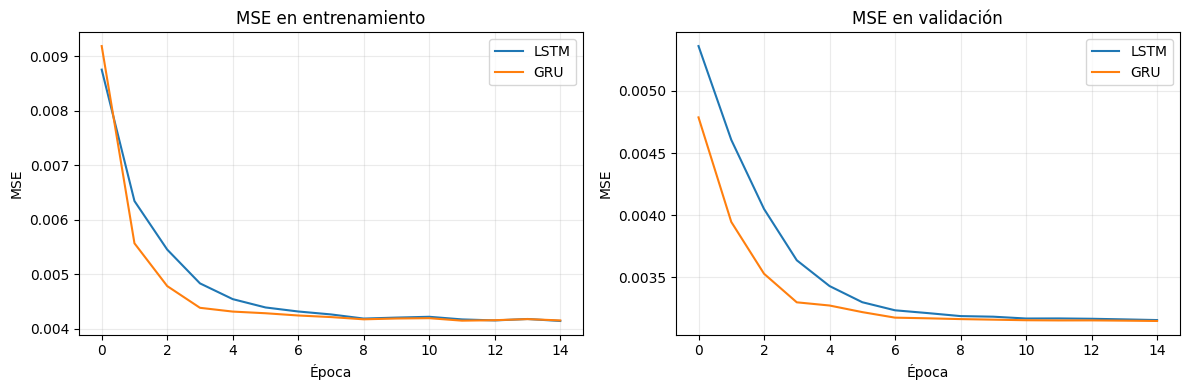

In [ ]:
# Comparación visual del error de entrenamiento y validación.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for tipo, historial in historias.items():
    axes[0].plot(historial.history['loss'], label=tipo)
    axes[1].plot(historial.history['val_loss'], label=tipo)
axes[0].set(title='MSE en entrenamiento', xlabel='Época', ylabel='MSE')
axes[1].set(title='MSE en validación', xlabel='Época', ylabel='MSE')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 7. Evaluación final en test

Se desnormalizan predicciones y valores reales antes de calcular **MAE** y **RMSE**, para expresar los errores en las unidades originales. Se incluye un baseline naive: pronosticar que el siguiente valor será igual al último observado.

In [ ]:
def desnormalizar(arr):
    return scaler.inverse_transform(np.asarray(arr).reshape(-1, 1)).ravel()

def medir(real, pred):
    return (mean_absolute_error(real, pred),
            np.sqrt(mean_squared_error(real, pred)))

y_real = desnormalizar(y_test)
predicciones = {}
filas = []

# Referencia mínima: repetir la última observación disponible.
predicciones['Naive'] = desnormalizar(X_test[:, -1, 0])
mae, rmse = medir(y_real, predicciones['Naive'])
filas.append({'Modelo': 'Naive', 'MAE': mae, 'RMSE': rmse,
              'Parámetros': 0, 'Tiempo (s)': 0.0})

for tipo, modelo in modelos.items():
    pred_norm = modelo.predict(X_test, verbose=0).ravel()
    predicciones[tipo] = desnormalizar(pred_norm)
    mae, rmse = medir(y_real, predicciones[tipo])
    filas.append({'Modelo': tipo, 'MAE': mae, 'RMSE': rmse,
                  'Parámetros': modelo.count_params(),
                  'Tiempo (s)': tiempos[tipo]})

tabla = pd.DataFrame(filas).sort_values('MAE').reset_index(drop=True)
print('Resultados en datos de prueba (unidades originales):')
display(tabla.round(3))
tabla.to_csv(RESULTADOS / '{project}_metricas.csv', index=False)

ganador = tabla.iloc[0]['Modelo']
print('Menor MAE:', ganador)
if ganador == 'Naive':
    print('En esta ejecución ningún modelo neuronal superó al baseline naive.')
else:
    print('En esta ejecución', ganador, 'obtuvo el menor MAE.')

Resultados en datos de prueba (unidades originales):


,Modelo,MAE,RMSE,Parámetros,Tiempo (s)
0,GRU,26.549,60.487,3393,44.723
1,LSTM,26.568,60.315,4385,38.340
2,Naive,26.738,66.837,0,0.000


Menor MAE: GRU
En esta ejecución GRU obtuvo el menor MAE.


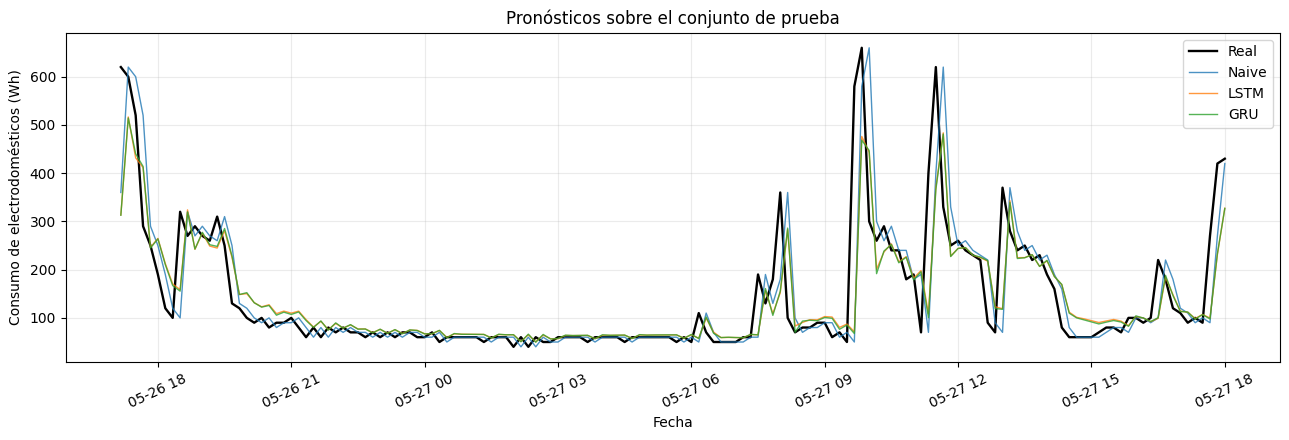

In [ ]:
# Valores reales frente a predicciones sobre las últimas observaciones de test.
tramo = min(150, len(y_real))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(t_test[-tramo:], y_real[-tramo:], color='black', label='Real', lw=1.7)
for tipo in ['Naive', 'LSTM', 'GRU']:
    ax.plot(t_test[-tramo:], predicciones[tipo][-tramo:],
            label=tipo, alpha=0.8, lw=1.0)
ax.set(title='Pronósticos sobre el conjunto de prueba',
       xlabel='Fecha', ylabel='Consumo de electrodomésticos (Wh)')
ax.legend(); ax.grid(alpha=0.25)
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(RESULTADOS / 'energia_pronosticos.png', dpi=150)
plt.show()

## 8. Interpretación de resultados

La tabla anterior permite comparar: **(a)** cuál obtuvo menor MAE/RMSE, **(b)** cuántos parámetros necesita LSTM frente a GRU, **(c)** el tiempo registrado y **(d)** si superaron o no al baseline naive. Las métricas no están escritas de antemano; dependen de los resultados reales obtenidos.

**Alcance:** se predice solo un paso hacia adelante usando observaciones anteriores reales. No se ha demostrado que un modelo funcione igual en otros años, ciudades o viviendas. Una arquitectura más compleja no garantiza menor error.

In [ ]:
# Resumen numérico directamente calculado, sin conclusiones prefijadas.
for _, fila in tabla.iterrows():
    print(f"{fila['Modelo']}: MAE={fila['MAE']:.2f} | "
          f"RMSE={fila['RMSE']:.2f} | "
          f"Parámetros={int(fila['Parámetros']):,} | "
          f"Entrenamiento={fila['Tiempo (s)']:.1f} s")

print('\nArchivos creados en:', RESULTADOS)

GRU: MAE=26.55 | RMSE=60.49 | Parámetros=3,393 | Entrenamiento=44.7 s
LSTM: MAE=26.57 | RMSE=60.32 | Parámetros=4,385 | Entrenamiento=38.3 s
Naive: MAE=26.74 | RMSE=66.84 | Parámetros=0 | Entrenamiento=0.0 s

Archivos creados en: /content/resultados_sesion10
